# Análise do desempenho escolar de estudantes

**Projeto individual - Ana de Kassia da Silva Soares — análise exploratória e teste de hipótese**

## Objetivo
Investigar fatores associados ao desempenho de estudantes na disciplina de Língua Portuguesa, usando a base pública *Student Performance*, disponibilizada pelo UCI Machine Learning Repository.

> A base original deve estar em `dados/student-por.csv`. Não altere esse arquivo. O notebook faz os tratamentos apenas em memória.

In [21]:
!pip install pandas numpy matplotlib seaborn scipy

In [22]:
import os

os.makedirs('dados', exist_ok=True)

In [23]:
import os
os.makedirs('dados', exist_ok=True)

print("Pasta de dados preparada.")

Pasta de dados preparada.


In [24]:
import os

print(os.listdir('dados'))

['student-por.csv']


In [25]:
import os

print("Pasta dados existe?", os.path.exists('dados'))
print("Arquivos encontrados:", os.listdir('dados'))

Pasta dados existe? True
Arquivos encontrados: ['student-por.csv']


In [26]:
print("Arquivo já está na pasta dados.")

Arquivo já está na pasta dados.


In [27]:
import pandas as pd

df = pd.read_csv('dados/student-por.csv', sep=';')

print("Quantidade de linhas e colunas:", df.shape)

display(df.head())

Quantidade de linhas e colunas: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


## 1. Base escolhida

A base *Student Performance* reúne informações de estudantes de duas escolas secundárias de Portugal. A versão de Língua Portuguesa contém 649 registros e variáveis demográficas, familiares, escolares e notas.

**Por que foi escolhida?** Ela permite investigar questões úteis para a gestão escolar, como a relação entre hábitos de estudo, faltas e desempenho. A análise pode ajudar a identificar grupos que merecem acompanhamento, sem afirmar causalidade.

Fonte: UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/320/student%2Bperformance

## 2. Perguntas de pesquisa e relevância para a gestão escolar

1. **Alunos que estudam mais horas por semana apresentam notas finais maiores?**  
   A avaliação da rotina de estudos está associada ao desempenho e a orientação das ações de incentivo ao estudo.

2. **O número de faltas está relacionado à nota final?**  
   Ajuda a apoiar políticas de acompanhamento de frequência e busca ativa de estudantes.

3. **Existe diferença estatisticamente significativa entre as notas finais de estudantes do sexo feminino e masculino?**  
   Esse dado permite verificar se há diferença observada entre grupos e se ela é compatível com variação amostral. O resultado não deve ser usado para estereótipos nem para decisões discriminatórias.

## 3. Preparação dos dados

A base é lida diretamente do arquivo original. Primeiro são examinadas dimensões, tipos, valores ausentes, duplicatas e faixas das variáveis principais. Se necessário, uma cópia em memória é preparada para a análise. Nenhuma alteração é gravada sobre o CSV original.

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

caminho = Path("dados/student-por.csv")
if not caminho.exists():
    raise FileNotFoundError(
        "Não encontrei dados/student-por.csv. Baixe a base original do UCI "
        "e salve esse arquivo dentro da pasta dados/."
    )

df_original = pd.read_csv(caminho, sep=";")
df = df_original.copy()

print("Dimensões (linhas, colunas):", df.shape)
display(df.head())

Dimensões (linhas, colunas): (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


In [29]:
print("Tipos de dados:")
display(df.dtypes.to_frame("tipo"))

print("Valores ausentes por coluna:")
display(df.isna().sum().to_frame("ausentes"))

print("Quantidade de linhas duplicadas:", df.duplicated().sum())

print("Resumo estatístico:")
display(df.describe(include="all").T)

Tipos de dados:


,tipo
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


Valores ausentes por coluna:


,ausentes
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Quantidade de linhas duplicadas: 0
Resumo estatístico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,649,2,GP,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,649,2,F,383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,649.0,NaN,NaN,NaN,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649,2,U,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,649,2,GT3,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,649,2,T,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,649.0,NaN,NaN,NaN,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,NaN,NaN,NaN,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649,5,other,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,649,5,other,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Tratamentos e critérios

- O separador do arquivo é ponto e vírgula (`;`).
- As colunas `G3`, `studytime`, `absences` e `sex` são mantidas com seus significados originais.
- Para cada análise, são removidas apenas as linhas que não tenham valor nas variáveis utilizadas naquela análise.
- A variável `studytime` é ordinal: 1 = menos de 2 horas; 2 = 2 a 5 horas; 3 = 5 a 10 horas; 4 = mais de 10 horas por semana.
- A nota final `G3` varia de 0 a 20.
- O arquivo original permanece sem alterações.

In [30]:
# Conferência das categorias e dos limites das variáveis utilizadas
print("Categorias de sexo:", sorted(df["sex"].dropna().unique()))
print("Categorias de tempo de estudo:", sorted(df["studytime"].dropna().unique()))
print("Faixa observada de G3:", df["G3"].min(), "a", df["G3"].max())
print("Faixa observada de faltas:", df["absences"].min(), "a", df["absences"].max())

# Cópia de trabalho com os campos essenciais válidos
colunas_essenciais = ["sex", "studytime", "absences", "G3"]
analise = df[colunas_essenciais].dropna().copy()
print("Registros disponíveis para as análises:", len(analise))

Categorias de sexo: ['F', 'M']
Categorias de tempo de estudo: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Faixa observada de G3: 0 a 19
Faixa observada de faltas: 0 a 32
Registros disponíveis para as análises: 649


## 4. Análise — pergunta 1

**Alunos que estudam mais horas por semana apresentam notas finais maiores?**

Será calculada a quantidade de estudantes, média, mediana e desvio-padrão da nota final em cada categoria de tempo de estudo. A comparação é descritiva: ela mostra associação, não prova que estudar mais horas, isoladamente, cause notas maiores.

,quantidade,media,mediana,desvio_padrao
faixa_estudo,,,,
Menos de 2h,212,10.84,11.0,3.22
2 a 5h,305,12.09,12.0,3.24
5 a 10h,97,13.23,13.0,2.50
Mais de 10h,35,13.06,13.0,3.04


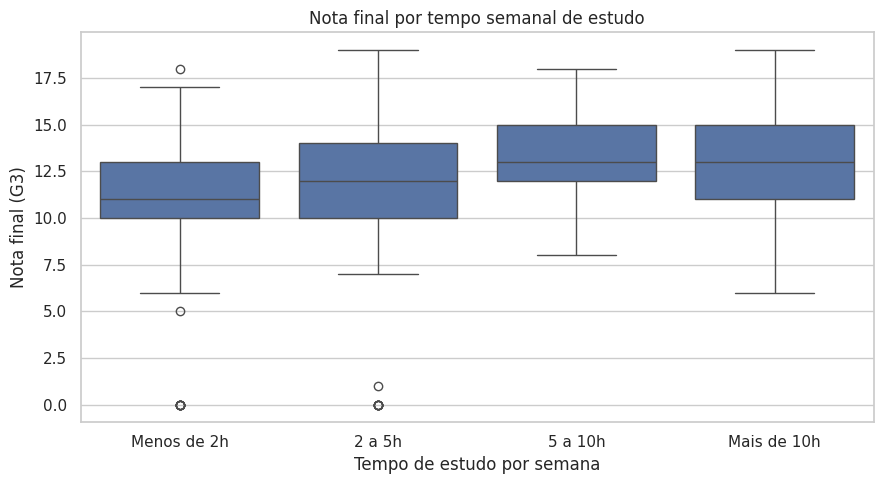

In [31]:
rotulos_estudo = {
    1: "Menos de 2h",
    2: "2 a 5h",
    3: "5 a 10h",
    4: "Mais de 10h"
}
q1 = analise.copy()
q1["faixa_estudo"] = q1["studytime"].map(rotulos_estudo)

resumo_estudo = q1.groupby("faixa_estudo", observed=False)["G3"].agg(
    quantidade="count", media="mean", mediana="median", desvio_padrao="std"
).reindex(list(rotulos_estudo.values()))
display(resumo_estudo.round(2))

ordem = list(rotulos_estudo.values())
plt.figure(figsize=(9, 5))
sns.boxplot(data=q1, x="faixa_estudo", y="G3", order=ordem)
plt.title("Nota final por tempo semanal de estudo")
plt.xlabel("Tempo de estudo por semana")
plt.ylabel("Nota final (G3)")
plt.tight_layout()
plt.show()

## 4. Análise — pergunta 2

**O número de faltas está relacionado à nota final?**

Será utilizada a correlação de Spearman, adequada para avaliar associação monotônica sem exigir relação linear. O gráfico de dispersão ajuda a visualizar a distribuição. Correlação não implica causalidade.

Correlação de Spearman: -0.159
Valor-p: 0.00005


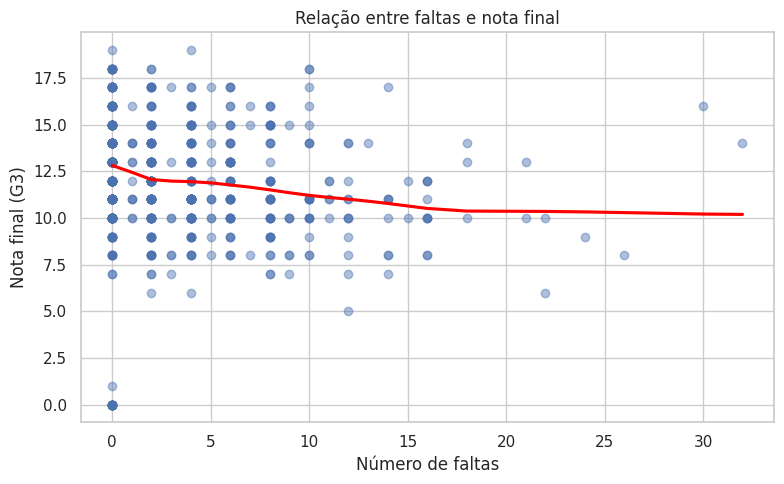

In [32]:
rho, p_spearman = stats.spearmanr(analise["absences"], analise["G3"])
print(f"Correlação de Spearman: {rho:.3f}")
print(f"Valor-p: {p_spearman:.5f}")

plt.figure(figsize=(8, 5))
sns.regplot(
    data=analise, x="absences", y="G3",
    lowess=True, scatter_kws={"alpha": 0.45}, line_kws={"color": "red"}
)
plt.title("Relação entre faltas e nota final")
plt.xlabel("Número de faltas")
plt.ylabel("Nota final (G3)")
plt.tight_layout()
plt.show()

## 4 e 6. Análise — pergunta 3 e teste de hipótese

**Existe diferença estatisticamente significativa entre as notas finais de estudantes do sexo feminino e masculino?**

- **H₀:** as distribuições das notas finais dos dois grupos não diferem (no teste de Mann–Whitney); se for utilizado o teste t, a hipótese nula é igualdade das médias.
- **H₁:** existe diferença entre os grupos.
- **Nível de significância:** 5% (`α = 0,05`).
- Os grupos são independentes.

O notebook verifica a normalidade em cada grupo com Shapiro-Wilk. Se ambos os grupos não apresentarem evidência contra a normalidade (p > 0,05), será aplicado o teste t de Welch, que não exige variâncias iguais. Caso contrário, será aplicado Mann–Whitney. A decisão e o teste efetivamente utilizado serão registrados abaixo.

In [33]:
grupo_f = analise.loc[analise["sex"] == "F", "G3"].astype(float)
grupo_m = analise.loc[analise["sex"] == "M", "G3"].astype(float)

print("Feminino — n:", len(grupo_f), "| média:", round(grupo_f.mean(), 2),
      "| mediana:", round(grupo_f.median(), 2), "| desvio-padrão:", round(grupo_f.std(), 2))
print("Masculino — n:", len(grupo_m), "| média:", round(grupo_m.mean(), 2),
      "| mediana:", round(grupo_m.median(), 2), "| desvio-padrão:", round(grupo_m.std(), 2))

# Diagnóstico de normalidade (Shapiro-Wilk)
shapiro_f = stats.shapiro(grupo_f)
shapiro_m = stats.shapiro(grupo_m)
print(f"Shapiro feminino: estatística={shapiro_f.statistic:.3f}, p={shapiro_f.pvalue:.5f}")
print(f"Shapiro masculino: estatística={shapiro_m.statistic:.3f}, p={shapiro_m.pvalue:.5f}")

alpha = 0.05
if shapiro_f.pvalue > alpha and shapiro_m.pvalue > alpha:
    resultado = stats.ttest_ind(grupo_f, grupo_m, equal_var=False)
    nome_teste = "Teste t de Welch"
    estatistica = resultado.statistic
    p_valor = resultado.pvalue
    hipotese_nula = "igualdade das médias"
else:
    resultado = stats.mannwhitneyu(grupo_f, grupo_m, alternative="two-sided")
    nome_teste = "Teste de Mann-Whitney"
    estatistica = resultado.statistic
    p_valor = resultado.pvalue
    hipotese_nula = "ausência de diferença entre as distribuições"

print("\nTeste aplicado:", nome_teste)
print("Estatística do teste:", round(estatistica, 4))
print("Valor-p:", f"{p_valor:.6f}")
print("Hipótese nula:", hipotese_nula)

if p_valor < alpha:
    print("Decisão: rejeitar H0. Há evidência estatística de diferença entre os grupos.")
else:
    print("Decisão: não rejeitar H0. Não há evidência estatística suficiente de diferença entre os grupos.")

Feminino — n: 383 | média: 12.25 | mediana: 12.0 | desvio-padrão: 3.12
Masculino — n: 266 | média: 11.41 | mediana: 11.0 | desvio-padrão: 3.32
Shapiro feminino: estatística=0.934, p=0.00000
Shapiro masculino: estatística=0.913, p=0.00000

Teste aplicado: Teste de Mann-Whitney
Estatística do teste: 58916.5
Valor-p: 0.000632
Hipótese nula: ausência de diferença entre as distribuições
Decisão: rejeitar H0. Há evidência estatística de diferença entre os grupos.


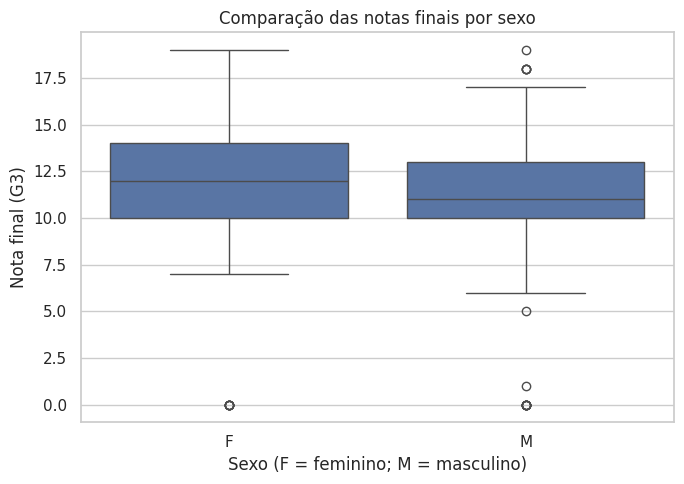

In [34]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=analise[analise["sex"].isin(["F", "M"])], x="sex", y="G3")
plt.title("Comparação das notas finais por sexo")
plt.xlabel("Sexo (F = feminino; M = masculino)")
plt.ylabel("Nota final (G3)")
plt.tight_layout()
plt.show()

## 5. Estatística e visualizações

As tabelas apresentam quantidade de observações, média, mediana e desvio-padrão. Os gráficos permitem comparar a distribuição das notas por tempo de estudo e por sexo, além de observar a relação entre faltas e nota final.

Ao interpretar:
- **Média:** valor médio das notas.
- **Mediana:** valor central, menos sensível a valores extremos.
- **Desvio-padrão:** dispersão das notas em torno da média.
- **Correlação de Spearman:** direção e intensidade da associação monotônica entre duas variáveis.
- **Valor-p:** mede a compatibilidade dos dados com a hipótese nula; não é a probabilidade de H₀ ser verdadeira.

## 7. Conclusões

Preencha esta seção após executar todas as células. Use os números calculados no notebook, sem antecipar resultados.

- **Tempo de estudo:** Observa-se uma tendência de aumento na média das notas finais conforme aumenta o tempo dedicado aos estudos. Os estudantes que estudam de 5 a 10 horas apresentam a maior média (13,23), enquanto aqueles que estudam menos de 2 horas apresentam a menor média (10,84). Isso sugere uma associação positiva entre tempo de estudo e desempenho escolar, embora não permita afirmar que estudar mais seja a causa direta das notas maiores.
- **Faltas:** Os resultados indicam uma correlação negativa fraca entre o número de faltas e as notas finais dos estudantes. Isso significa que, em geral, quanto maior o número de faltas, menor tende a ser a nota final. O valor-p de 0,00005 demonstra que essa associação é estatisticamente significativa. Entretanto, a correlação é fraca e não permite afirmar que as faltas sejam a única causa da redução do desempenho escolar.
- **Comparação entre grupos:** Os resultados demonstram que existe uma diferença estatisticamente significativa entre as notas finais dos estudantes do sexo feminino e masculino. O grupo feminino apresentou média de 12,25, enquanto o grupo masculino apresentou média de 11,41. Como o teste de Mann-Whitney apresentou valor-p de 0,000632, inferior ao nível de significância de 0,05, rejeita-se a hipótese nula. Portanto, há evidências estatísticas de diferença entre as distribuições das notas dos dois grupos, com resultados mais elevados entre as estudantes do sexo feminino nesta amostra.
- **Implicação para a gestão:** A gestão escolar pode utilizar esses resultados para incentivar hábitos de estudo, acompanhar a frequência dos alunos e identificar dificuldades de aprendizagem, desenvolvendo ações que contribuam para melhorar o desempenho escolar e garantir oportunidades iguais para todos.

## 8. Reflexão

**O que ficou mais fácil em Python do que em uma planilha?**  
A ser preenchido com a experiência real: por exemplo, repetir cálculos, agrupar registros, aplicar testes estatísticos e gerar gráficos com comandos reproduzíveis.

**Como a equipe dividiu o trabalho?**  
Este projeto foi desenvolvido individualmente.

## Referências

- Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T
- UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/320/student%2Bperformance

